## 1. Imports

In [3]:
import os, random, copy, time, json
from pathlib import Path
import cv2, numpy as np, pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, roc_auc_score

## 2. Configuration 

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
GPU_COUNT = torch.cuda.device_count() if torch.cuda.is_available() else 0
USE_MULTI_GPU = GPU_COUNT > 1

INPUT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/deepfake_gan_detector")

FRAME_DIR = WORK_DIR / "video_frames"
ENHANCED_DIR = WORK_DIR / "enhanced_frames"
MODEL_DIR = WORK_DIR / "models"

for folder in [FRAME_DIR, ENHANCED_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv"}

FRAMES_PER_VIDEO = 5
IMAGE_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 35
USE_PRETRAINED = True

print("Device:", DEVICE)
print("Working directory:", WORK_DIR)
print("Multi-GPU training:", USE_MULTI_GPU)

if torch.cuda.is_available():
    print("Number of GPUs:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

Device: cuda:0
Working directory: /kaggle/working/deepfake_gan_detector
Multi-GPU training: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Find the dataset folders

In [5]:
original_candidates = [
    p for p in INPUT.rglob("original")
    if p.is_dir() and any(q.is_dir() for q in p.parent.iterdir())
]
if not original_candidates:
    raise FileNotFoundError("Could not find an 'original' video folder under /kaggle/input.")
REAL_VIDEO_DIR = original_candidates[0]
DATA_ROOT = REAL_VIDEO_DIR.parent
print("Real videos:", REAL_VIDEO_DIR)
print("Dataset root:", DATA_ROOT)
print("Root folders:", [p.name for p in DATA_ROOT.iterdir()][:30])

Real videos: /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/original
Dataset root: /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
Root folders: ['Face2Face', 'csv', 'Deepfakes', 'DeepFakeDetection', 'original', 'NeuralTextures', 'FaceShifter', 'FaceSwap']


## 4. Discover videos

In [6]:
def find_videos(folder):
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VIDEO_EXTS
    )

real_videos = find_videos(REAL_VIDEO_DIR)
fake_methods = ["DeepFakeDetection", "Deepfakes", "Face2Face",
                "FaceShifter", "FaceSwap", "NeuralTextures"]
fake_by_method = {name: find_videos(DATA_ROOT / name) for name in fake_methods}
print("Real videos:", len(real_videos))
print("Fake videos by method:", {k: len(v) for k, v in fake_by_method.items()})

Real videos: 1000
Fake videos by method: {'DeepFakeDetection': 1000, 'Deepfakes': 1000, 'Face2Face': 1000, 'FaceShifter': 1000, 'FaceSwap': 1000, 'NeuralTextures': 1000}


In [7]:
MAX_REAL = 500
MAX_FAKE_TOTAL = 500

rng = random.Random(SEED)

selected_real = rng.sample(
    real_videos,
    min(MAX_REAL, len(real_videos))
)

available_fake_methods = {
    method: paths
    for method, paths in fake_by_method.items()
    if paths
}

if not available_fake_methods:
    raise RuntimeError("No fake videos were found.")

selected_fake = []
method_names = list(available_fake_methods)
rng.shuffle(method_names)

# Split the fake-video limit across the available methods.
quotas = {
    method: MAX_FAKE_TOTAL // len(method_names)
    for method in method_names
}

for method in method_names[:MAX_FAKE_TOTAL % len(method_names)]:
    quotas[method] += 1

for method in method_names:
    paths = available_fake_methods[method]
    chosen = rng.sample(paths, min(quotas[method], len(paths)))
    selected_fake.extend(
        (str(path), 1, method)
        for path in chosen
    )

# Fill any unused quota from the remaining fake videos.
remaining = MAX_FAKE_TOTAL - len(selected_fake)

if remaining > 0:
    already_selected = {record[0] for record in selected_fake}

    leftovers = [
        (str(path), 1, method)
        for method, paths in available_fake_methods.items()
        for path in paths
        if str(path) not in already_selected
    ]

    selected_fake.extend(
        rng.sample(leftovers, min(remaining, len(leftovers)))
    )

# Real = 0; Fake = 1.
records = [
    (str(path), 0, "original")
    for path in selected_real
] + selected_fake

video_df = pd.DataFrame(
    records,
    columns=["video_path", "label", "method"]
)

video_df["video_id"] = video_df["video_path"]

print("Selected videos:", len(video_df))
print("\nVideos by method and label:")
print(video_df.groupby(["method", "label"]).size())
print("\nClass totals:")
print(video_df["label"].value_counts().sort_index())

assert set(video_df["label"].unique()).issubset({0, 1})

Selected videos: 1000

Videos by method and label:
method             label
DeepFakeDetection  1         83
Deepfakes          1         84
Face2Face          1         83
FaceShifter        1         83
FaceSwap           1         83
NeuralTextures     1         84
original           0        500
dtype: int64

Class totals:
label
0    500
1    500
Name: count, dtype: int64


## 5. Train/validation split by video

In [8]:
train_videos, val_videos = train_test_split(
    video_df, test_size=0.2, random_state=SEED,
    stratify=video_df["label"]
)
train_ids = set(train_videos["video_id"])
val_ids = set(val_videos["video_id"])
print("Train videos:", len(train_videos))
print("Validation videos:", len(val_videos))

Train videos: 800
Validation videos: 200


## 6. Extract frames (complete function in this cell)

In [9]:
def extract_video_frames(video_path, out_dir, count=FRAMES_PER_VIDEO):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return []
    indices = np.linspace(0, total - 1, min(count, total), dtype=int)
    saved = []
    for j, idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if not ok:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (IMAGE_SIZE, IMAGE_SIZE))
        out_path = out_dir / f"frame_{j:02d}.jpg"
        Image.fromarray(frame).save(out_path, quality=95)
        saved.append(str(out_path))
    cap.release()
    return saved

## 7. Create or reuse the frame manifest

In [10]:
frame_table_path = WORK_DIR / "video_frames_index.csv"

frame_columns = ["path", "label", "video_id", "method"]
expected_video_ids = set(video_df["video_id"])

if frame_table_path.exists():
    frame_table = pd.read_csv(frame_table_path)

    valid_cache = (
        set(frame_columns).issubset(frame_table.columns)
        and not frame_table.empty
        and frame_table["path"].map(
            lambda path: Path(path).exists()
        ).all()
        and set(frame_table["video_id"].unique()) == expected_video_ids
    )

    if not valid_cache:
        frame_table_path.unlink()
        frame_table = pd.DataFrame(columns=frame_columns)
else:
    frame_table = pd.DataFrame(columns=frame_columns)

In [11]:
if frame_table.empty:
    rows = []
    total_videos = len(video_df)

    for i, row in enumerate(video_df.itertuples(index=False), start=1):
        folder_name = f"{row.label}_{row.method}_{i:05d}"
        output_folder = FRAME_DIR / folder_name

        image_paths = extract_video_frames(
            row.video_path,
            output_folder
        )

        for image_path in image_paths:
            rows.append((
                image_path,
                row.label,
                row.video_id,
                row.method
            ))

        if i % 25 == 0 or i == total_videos:
            print(f"Processed {i}/{total_videos} videos")

    frame_table = pd.DataFrame(rows, columns=frame_columns)
    frame_table.to_csv(frame_table_path, index=False)

print("Frames ready:", len(frame_table))
print("Frame index:", frame_table_path)

if frame_table.empty:
    raise RuntimeError(
        "No frames were extracted. Check the video paths."
    )

Processed 25/1000 videos
Processed 50/1000 videos
Processed 75/1000 videos
Processed 100/1000 videos
Processed 125/1000 videos
Processed 150/1000 videos
Processed 175/1000 videos
Processed 200/1000 videos
Processed 225/1000 videos
Processed 250/1000 videos
Processed 275/1000 videos
Processed 300/1000 videos
Processed 325/1000 videos
Processed 350/1000 videos
Processed 375/1000 videos
Processed 400/1000 videos
Processed 425/1000 videos
Processed 450/1000 videos
Processed 475/1000 videos
Processed 500/1000 videos
Processed 525/1000 videos
Processed 550/1000 videos
Processed 575/1000 videos
Processed 600/1000 videos
Processed 625/1000 videos
Processed 650/1000 videos
Processed 675/1000 videos
Processed 700/1000 videos
Processed 725/1000 videos
Processed 750/1000 videos
Processed 775/1000 videos
Processed 800/1000 videos
Processed 825/1000 videos
Processed 850/1000 videos
Processed 875/1000 videos
Processed 900/1000 videos
Processed 925/1000 videos
Processed 950/1000 videos
Processed 975/1

## 8. Create split-specific frame tables

In [12]:
train_df = (
    frame_table[frame_table["video_id"].isin(train_ids)]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    frame_table[frame_table["video_id"].isin(val_ids)]
    .copy()
    .reset_index(drop=True)
)

print("Training frames:", len(train_df))
print("Validation frames:", len(val_df))

assert set(train_df["video_id"]).isdisjoint(
    set(val_df["video_id"])
)

assert set(train_df["label"].unique()).issubset({0, 1})
assert set(val_df["label"].unique()).issubset({0, 1})

Training frames: 4000
Validation frames: 1000


## 9. Find and load the trained GAN

In [13]:
GAN_CHECKPOINT = None
for filename in ["enhancement_best.pth", "enhancement_latest.pth"]:
    matches = list(INPUT.rglob(filename))
    if matches:
        GAN_CHECKPOINT = matches[0]
        break
print("GAN checkpoint:", GAN_CHECKPOINT)
if GAN_CHECKPOINT is None:
    raise FileNotFoundError("Attach a GAN output containing enhancement_best.pth or enhancement_latest.pth.")

GAN checkpoint: /kaggle/input/models/zunzurkarchaitanya/gan-for-deepfake-detection/pytorch/default/1/enhancement_best.pth


### Generator architecture — matches the GAN training notebook

In [14]:
class ResidualBlock(nn.Module):
    def __init__(self, channels=48):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, 1, 1),
            nn.BatchNorm2d(channels),
            nn.PReLU(channels),
            nn.Conv2d(channels, channels, 3, 1, 1),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        return x + 0.2 * self.block(x)


class EnhancementGenerator(nn.Module):
    def __init__(self, channels=48, blocks=6):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, channels, 9, 1, 4), nn.PReLU(channels))
        self.body = nn.Sequential(*[ResidualBlock(channels) for _ in range(blocks)])
        self.body_tail = nn.Sequential(nn.Conv2d(channels, channels, 3, 1, 1), nn.BatchNorm2d(channels))
        self.output = nn.Conv2d(channels, 3, 9, 1, 4)

    def forward(self, x):
        features = self.head(x)
        refined = features + self.body_tail(self.body(features))
        return (x + 0.25 * torch.tanh(self.output(refined))).clamp(0.0, 1.0)

In [15]:
checkpoint = torch.load(GAN_CHECKPOINT, map_location="cpu", weights_only=False)
G = EnhancementGenerator().to(DEVICE)
G.load_state_dict(checkpoint["G"])

if USE_MULTI_GPU:
    G = nn.DataParallel(G, device_ids=list(range(GPU_COUNT)))

G.eval()
print("Loaded GAN checkpoint:", GAN_CHECKPOINT)
print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))
print("GAN uses multiple GPUs:", isinstance(G, nn.DataParallel))

Loaded GAN checkpoint: /kaggle/input/models/zunzurkarchaitanya/gan-for-deepfake-detection/pytorch/default/1/enhancement_best.pth
Checkpoint epoch: 17
GAN uses multiple GPUs: True


## 10. Generate enhanced frames (cached)

In [16]:
enhanced_table_path = WORK_DIR / "enhanced_frames_index.csv"
enhanced_columns = ["path", "label", "video_id", "method"]

if enhanced_table_path.exists():
    enhanced_df = pd.read_csv(enhanced_table_path)

    valid_cache = (
        set(enhanced_columns).issubset(enhanced_df.columns)
        and len(enhanced_df) == len(frame_table)
        and enhanced_df["path"].map(
            lambda path: Path(path).exists()
        ).all()
        and set(enhanced_df["video_id"].unique())
        == set(frame_table["video_id"].unique())
    )

    if not valid_cache:
        enhanced_table_path.unlink()
        enhanced_df = pd.DataFrame(columns=enhanced_columns)
else:
    enhanced_df = pd.DataFrame(columns=enhanced_columns)

print("Saved enhanced frames:", len(enhanced_df))

Saved enhanced frames: 0


In [17]:
if enhanced_df.empty:
    enhanced_rows = []
    to_tensor = transforms.ToTensor()
    frame_records = list(frame_table.itertuples(index=False))

    G.eval()

    with torch.no_grad():
        for start in range(0, len(frame_records), BATCH_SIZE):
            batch_records = frame_records[start:start + BATCH_SIZE]
            batch_images = []

            for row in batch_records:
                with Image.open(row.path) as image:
                    image = image.convert("RGB")
                    batch_images.append(to_tensor(image))

            image_batch = torch.stack(batch_images).to(DEVICE)
            enhanced_batch = G(image_batch).cpu().clamp(0, 1)

            for row, enhanced_image in zip(batch_records, enhanced_batch):
                output_folder = ENHANCED_DIR / Path(row.path).parent.name
                output_folder.mkdir(parents=True, exist_ok=True)

                output_path = (
                    output_folder / f"{Path(row.path).stem}_enh.jpg"
                )

                transforms.ToPILImage()(enhanced_image).save(
                    output_path,
                    quality=95
                )

                enhanced_rows.append((
                    str(output_path),
                    int(row.label),
                    row.video_id,
                    row.method
                ))

            processed = min(start + len(batch_records), len(frame_records))
            if processed % 100 == 0 or processed == len(frame_records):
                print(f"Enhanced {processed}/{len(frame_records)} frames")

    enhanced_df = pd.DataFrame(
        enhanced_rows,
        columns=enhanced_columns
    )

    enhanced_df.to_csv(enhanced_table_path, index=False)

print("Enhanced frames ready:", len(enhanced_df))

assert set(enhanced_df["label"].unique()).issubset({0, 1})

Enhanced 400/5000 frames
Enhanced 800/5000 frames
Enhanced 1200/5000 frames
Enhanced 1600/5000 frames
Enhanced 2000/5000 frames
Enhanced 2400/5000 frames
Enhanced 2800/5000 frames
Enhanced 3200/5000 frames
Enhanced 3600/5000 frames
Enhanced 4000/5000 frames
Enhanced 4400/5000 frames
Enhanced 4800/5000 frames
Enhanced 5000/5000 frames
Enhanced frames ready: 5000


## 11. Dataset classes and loaders

In [18]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch


TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.01
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation uses deterministic preprocessing.
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class FrameDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform or EVAL_TRANSFORM

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label, row["video_id"]


print("Training and evaluation transforms configured.")
IMAGE_TRANSFORM = EVAL_TRANSFORM

Training and evaluation transforms configured.


In [19]:
# Split enhanced frames using the same video split.
train_enh = (
    enhanced_df[enhanced_df["video_id"].isin(train_ids)]
    .copy()
    .reset_index(drop=True)
)

val_enh = (
    enhanced_df[enhanced_df["video_id"].isin(val_ids)]
    .copy()
    .reset_index(drop=True)
)

BATCH_SIZE = 16

train_orig_loader = DataLoader(
    FrameDataset(train_df, transform=TRAIN_TRANSFORM),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_orig_loader = DataLoader(
    FrameDataset(val_df, transform=EVAL_TRANSFORM),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

train_enh_loader = DataLoader(
    FrameDataset(train_enh, transform=TRAIN_TRANSFORM),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_enh_loader = DataLoader(
    FrameDataset(val_enh, transform=EVAL_TRANSFORM),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Original training frames:", len(train_df))
print("Original validation frames:", len(val_df))
print("Enhanced training frames:", len(train_enh))
print("Enhanced validation frames:", len(val_enh))

assert set(train_df["video_id"]).isdisjoint(set(val_df["video_id"]))
assert set(train_enh["video_id"]).isdisjoint(set(val_enh["video_id"]))

assert set(train_df["label"].unique()).issubset({0, 1})
assert set(val_df["label"].unique()).issubset({0, 1})
assert set(train_enh["label"].unique()).issubset({0, 1})
assert set(val_enh["label"].unique()).issubset({0, 1})

print("Data loaders are ready.")

Original training frames: 4000
Original validation frames: 1000
Enhanced training frames: 4000
Enhanced validation frames: 1000
Data loaders are ready.


## 12. CNN model classes

In [20]:
def make_backbone(pretrained=USE_PRETRAINED):
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    backbone = models.efficientnet_b0(weights=weights)
    backbone.classifier = nn.Identity()
    return backbone


class SingleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = make_backbone()
        self.head = nn.Linear(1280, 2)

    def forward(self, x):
        return self.head(self.backbone(x))

In [21]:
class FusionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.original = make_backbone()
        self.enhanced = make_backbone()
        self.head = nn.Sequential(
            nn.Linear(2560, 512), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(512, 2)
        )

    def forward(self, original, enhanced):
        original_features = self.original(original)
        enhanced_features = self.enhanced(enhanced)
        combined = torch.cat([original_features, enhanced_features], dim=1)
        return self.head(combined)

## 13. Training and evaluation helpers

In [22]:
def score_model(model, loader):
    model.eval()

    labels = []
    predictions = []
    fake_probabilities = []

    with torch.no_grad():
        for images, targets, _ in loader:
            images = images.to(DEVICE)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            labels.extend(targets.cpu().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            fake_probabilities.extend(
                probabilities[:, 1].cpu().tolist()
            )

    metrics = {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "report": classification_report(
            labels,
            predictions,
            labels=[0, 1],
            target_names=["Real", "Fake"],
            zero_division=0
        )
    }

    if len(set(labels)) == 2:
        metrics["roc_auc"] = roc_auc_score(
            labels,
            fake_probabilities
        )
    else:
        metrics["roc_auc"] = float("nan")

    return metrics

In [23]:
def prepare_model_for_training(model):
    model = model.to(DEVICE)

    if USE_MULTI_GPU:
        model = nn.DataParallel(model, device_ids=list(range(GPU_COUNT)))

    return model


def unwrap_model(model):
    if isinstance(model, nn.DataParallel):
        return model.module
    return model


print("CNN training uses multiple GPUs:", USE_MULTI_GPU)

CNN training uses multiple GPUs: True


In [24]:
def train_single(model,train_loader,val_loader,name,epochs=EPOCHS,patience=8,head_only_epochs=3):
    model = prepare_model_for_training(model)
    core_model = unwrap_model(model)

    loss_fn = nn.CrossEntropyLoss()

    for param in core_model.backbone.parameters():
        param.requires_grad = False

    for param in core_model.head.parameters():
        param.requires_grad = True

    optimizer = torch.optim.AdamW(
        core_model.head.parameters(),
        lr=3e-4,
        weight_decay=1e-4
    )

    best_auc = -float("inf")
    best_state = copy.deepcopy(core_model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):

        if epoch == head_only_epochs:
            print("\nUnfreezing later EfficientNet layers...")

            for param in core_model.backbone.features[6:].parameters():
                param.requires_grad = True

            optimizer = torch.optim.AdamW(
                [
                    {
                        "params": [
                            p for p in core_model.backbone.parameters()
                            if p.requires_grad
                        ],
                        "lr": 1e-5
                    },
                    {
                        "params": core_model.head.parameters(),
                        "lr": 1e-4
                    }
                ],
                weight_decay=1e-4
            )

        model.train()

        # Keep frozen backbone BatchNorm statistics stable during stage 1.
        if epoch < head_only_epochs:
            core_model.backbone.eval()
            core_model.head.train()

        running_loss = 0.0

        for images, labels, _ in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = loss_fn(logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # Evaluate without training augmentation.
        metrics = score_model(model, val_loader)

        val_auc = metrics.get("roc_auc", float("nan"))
        val_f1 = metrics["f1"]
        avg_loss = running_loss / max(1, len(train_loader))

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} "
            f"| Train Loss: {avg_loss:.4f} "
            f"| Val F1: {val_f1:.4f} "
            f"| Val AUC: {val_auc:.4f}"
        )

        # AUC is the primary checkpoint selection metric.
        # If AUC is unavailable, fall back to macro-F1.
        score = val_auc if np.isfinite(val_auc) else val_f1

        if score > best_auc:
            best_auc = score
            best_state = copy.deepcopy(core_model.state_dict())
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_name": name,
                    "state_dict": best_state,
                    "best_validation_auc": (
                        float(val_auc)
                        if np.isfinite(val_auc)
                        else None
                    ),
                    "best_validation_f1": float(val_f1),
                    "class_names": ["Real", "Fake"],
                    "class_to_idx": {
                        "Real": 0,
                        "Fake": 1
                    }
                },
                MODEL_DIR / f"{name}_best.pth"
            )

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(
                f"Early stopping at epoch {epoch + 1}. "
                f"Best validation score: {best_auc:.4f}"
            )
            break

    # Restore the best checkpoint, not the final epoch.
    core_model.load_state_dict(best_state)

    print(f"\n{name} training completed.")
    print(f"Best validation selection score: {best_auc:.4f}")

    return model

## 14. Train Model 1 — original frames

In [25]:
model_original = SingleCNN()

model_original = train_single(
    model=model_original,
    train_loader=train_orig_loader,
    val_loader=val_orig_loader,
    name="cnn_original",
    epochs=EPOCHS,
    patience=8,
    head_only_epochs=3
)

original_metrics = score_model(
    model_original,
    val_orig_loader
)

print("\nM1 — ORIGINAL IMAGE RESULTS")
print(original_metrics["report"])
print("Accuracy:", original_metrics["accuracy"])
print("Macro F1:", original_metrics["f1"])
print("ROC-AUC:", original_metrics["roc_auc"])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 204MB/s]


cnn_original | Epoch 1/35 | Train Loss: 0.6524 | Val F1: 0.5025 | Val AUC: 0.5340
cnn_original | Epoch 2/35 | Train Loss: 0.6024 | Val F1: 0.4748 | Val AUC: 0.5066
cnn_original | Epoch 3/35 | Train Loss: 0.5734 | Val F1: 0.4737 | Val AUC: 0.5098

Unfreezing later EfficientNet layers...
cnn_original | Epoch 4/35 | Train Loss: 0.6447 | Val F1: 0.5253 | Val AUC: 0.5594
cnn_original | Epoch 5/35 | Train Loss: 0.6194 | Val F1: 0.5185 | Val AUC: 0.5379
cnn_original | Epoch 6/35 | Train Loss: 0.5919 | Val F1: 0.4945 | Val AUC: 0.5153
cnn_original | Epoch 7/35 | Train Loss: 0.5667 | Val F1: 0.4676 | Val AUC: 0.5032
cnn_original | Epoch 8/35 | Train Loss: 0.5454 | Val F1: 0.4801 | Val AUC: 0.4967
cnn_original | Epoch 9/35 | Train Loss: 0.5299 | Val F1: 0.4794 | Val AUC: 0.4904
cnn_original | Epoch 10/35 | Train Loss: 0.5107 | Val F1: 0.4895 | Val AUC: 0.4919
cnn_original | Epoch 11/35 | Train Loss: 0.4899 | Val F1: 0.4674 | Val AUC: 0.4927
cnn_original | Epoch 12/35 | Train Loss: 0.4665 | Val F

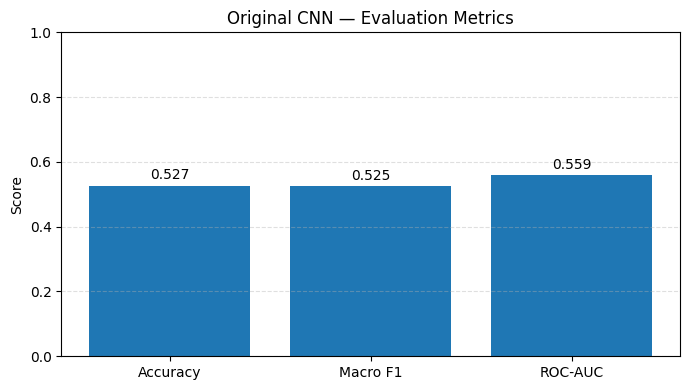

In [26]:
import matplotlib.pyplot as plt
import numpy as np

metrics = {
    "Accuracy": original_metrics["accuracy"],
    "Macro F1": original_metrics["f1"],
    "ROC-AUC": original_metrics.get("roc_auc", np.nan)
}

plt.figure(figsize=(7, 4))
bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Original CNN — Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, metrics.values()):
    if np.isfinite(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

## 15. Train Model 2 — GAN-enhanced frames

In [27]:
model_enhanced = SingleCNN()

model_enhanced = train_single(
    model=model_enhanced,
    train_loader=train_enh_loader,
    val_loader=val_enh_loader,
    name="cnn_enhanced",
    epochs=EPOCHS,
    patience=8,
    head_only_epochs=3
)

enhanced_metrics = score_model(
    model_enhanced,
    val_enh_loader
)

print("\nM2 — GAN-ENHANCED RESULTS")
print(enhanced_metrics["report"])
print("Accuracy:", enhanced_metrics["accuracy"])
print("Macro F1:", enhanced_metrics["f1"])
print("ROC-AUC:", enhanced_metrics["roc_auc"])

cnn_enhanced | Epoch 1/35 | Train Loss: 0.6607 | Val F1: 0.5075 | Val AUC: 0.5190
cnn_enhanced | Epoch 2/35 | Train Loss: 0.6050 | Val F1: 0.4835 | Val AUC: 0.4963
cnn_enhanced | Epoch 3/35 | Train Loss: 0.5740 | Val F1: 0.4880 | Val AUC: 0.4858

Unfreezing later EfficientNet layers...
cnn_enhanced | Epoch 4/35 | Train Loss: 0.6519 | Val F1: 0.5103 | Val AUC: 0.5468
cnn_enhanced | Epoch 5/35 | Train Loss: 0.6204 | Val F1: 0.5130 | Val AUC: 0.5377
cnn_enhanced | Epoch 6/35 | Train Loss: 0.5939 | Val F1: 0.4929 | Val AUC: 0.5250
cnn_enhanced | Epoch 7/35 | Train Loss: 0.5672 | Val F1: 0.4896 | Val AUC: 0.5070
cnn_enhanced | Epoch 8/35 | Train Loss: 0.5474 | Val F1: 0.4908 | Val AUC: 0.5031
cnn_enhanced | Epoch 9/35 | Train Loss: 0.5281 | Val F1: 0.4870 | Val AUC: 0.5013
cnn_enhanced | Epoch 10/35 | Train Loss: 0.5049 | Val F1: 0.4980 | Val AUC: 0.5019
cnn_enhanced | Epoch 11/35 | Train Loss: 0.4851 | Val F1: 0.4898 | Val AUC: 0.4961
cnn_enhanced | Epoch 12/35 | Train Loss: 0.4701 | Val F

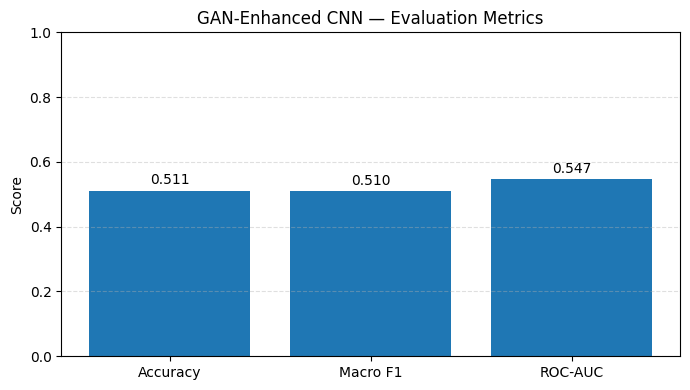

In [28]:
metrics = {
    "Accuracy": enhanced_metrics["accuracy"],
    "Macro F1": enhanced_metrics["f1"],
    "ROC-AUC": enhanced_metrics.get("roc_auc", np.nan)
}

plt.figure(figsize=(7, 4))
bars = plt.bar(metrics.keys(), metrics.values())

plt.title("GAN-Enhanced CNN — Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, metrics.values()):
    if np.isfinite(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

## 16. Fusion dataset (complete class in this cell)

In [29]:
class FusionDataset(Dataset):
    def __init__(self, original_df, enhanced_df):
        self.original_df = original_df.reset_index(drop=True)
        self.enhanced_paths = {}
        for row in enhanced_df.itertuples(index=False):
            original_stem = Path(row.path).stem.removesuffix("_enh")
            self.enhanced_paths[(row.video_id, original_stem)] = row.path

    def __len__(self):
        return len(self.original_df)

    def __getitem__(self, index):
        row = self.original_df.iloc[index]
        key = (row["video_id"], Path(row["path"]).stem)
        enhanced_path = self.enhanced_paths.get(key)
        if enhanced_path is None:
            raise FileNotFoundError(f"No enhanced frame matched {key}")
        original = IMAGE_TRANSFORM(Image.open(row["path"]).convert("RGB"))
        enhanced = IMAGE_TRANSFORM(Image.open(enhanced_path).convert("RGB"))
        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return original, enhanced, label

## 17. Fusion training and evaluation

In [30]:
def eval_fusion(model, loader):
    model.eval()
    labels, predictions, probabilities = [], [], []

    with torch.no_grad():
        for original, enhanced, targets in loader:
            original = original.to(DEVICE)
            enhanced = enhanced.to(DEVICE)

            logits = model(original, enhanced)

            # Predicted classes
            predictions.extend(logits.argmax(dim=1).cpu().tolist())

            # Probability of the Fake class (class 1)
            fake_probs = torch.softmax(logits, dim=1)[:, 1]
            probabilities.extend(fake_probs.cpu().tolist())

            labels.extend(targets.cpu().tolist())

    # ROC-AUC requires both classes to be present
    roc_auc = (
        roc_auc_score(labels, probabilities)
        if len(set(labels)) == 2
        else float("nan")
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),
        "roc_auc": roc_auc,
        "report": classification_report(
            labels, predictions,
            labels=[0, 1],
            target_names=["Real", "Fake"],
            zero_division=0
        ),
    }

In [31]:
def train_fusion(model,train_loader,val_loader,epochs=EPOCHS,patience=8,head_only_epochs=3):
    model = prepare_model_for_training(model)
    core_model = unwrap_model(model)
    loss_fn = nn.CrossEntropyLoss()

    # Initially freeze both feature extractors.
    for param in core_model.original.parameters():
        param.requires_grad = False

    for param in core_model.enhanced.parameters():
        param.requires_grad = False

    for param in core_model.head.parameters():
        param.requires_grad = True

    optimizer = torch.optim.AdamW(
        core_model.head.parameters(),
        lr=3e-4,
        weight_decay=1e-4
    )

    best_score = -float("inf")
    best_state = copy.deepcopy(core_model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):

        # Unfreeze the later layers of both feature extractors.
        if epoch == head_only_epochs:
            print("\nUnfreezing later fusion-backbone layers...")

            for param in core_model.original.features[6:].parameters():
                param.requires_grad = True

            for param in core_model.enhanced.features[6:].parameters():
                param.requires_grad = True

            optimizer = torch.optim.AdamW(
                [
                    {
                        "params": [
                            p for p in core_model.original.parameters()
                            if p.requires_grad
                        ],
                        "lr": 1e-5
                    },
                    {
                        "params": [
                            p for p in core_model.enhanced.parameters()
                            if p.requires_grad
                        ],
                        "lr": 1e-5
                    },
                    {
                        "params": core_model.head.parameters(),
                        "lr": 1e-4
                    }
                ],
                weight_decay=1e-4
            )

        model.train()

        if epoch < head_only_epochs:
            core_model.original.eval()
            core_model.enhanced.eval()
            core_model.head.train()

        running_loss = 0.0

        for original, enhanced, labels in train_loader:
            original = original.to(DEVICE)
            enhanced = enhanced.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(original, enhanced)
            loss = loss_fn(logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        metrics = eval_fusion(model, val_loader)

        val_auc = metrics.get("roc_auc", float("nan"))
        val_f1 = metrics["f1"]
        avg_loss = running_loss / max(1, len(train_loader))

        print(
            f"Fusion | Epoch {epoch + 1}/{epochs} "
            f"| Train Loss: {avg_loss:.4f} "
            f"| Val F1: {val_f1:.4f} "
            f"| Val AUC: {val_auc:.4f}"
        )

        score = val_auc if np.isfinite(val_auc) else val_f1

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(core_model.state_dict())
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_name": "cnn_feature_fusion",
                    "state_dict": best_state,
                    "best_validation_auc": (
                        float(val_auc)
                        if np.isfinite(val_auc)
                        else None
                    ),
                    "best_validation_f1": float(val_f1),
                    "class_names": ["Real", "Fake"],
                    "class_to_idx": {
                        "Real": 0,
                        "Fake": 1
                    }
                },
                MODEL_DIR / "cnn_feature_fusion_best.pth"
            )

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(
                f"Fusion early stopping at epoch {epoch + 1}. "
                f"Best validation score: {best_score:.4f}"
            )
            break

    core_model.load_state_dict(best_state)

    print("\nFusion training completed.")
    print("Best validation selection score:", best_score)

    return model

In [32]:
fusion_train_loader = DataLoader(
    FusionDataset(train_df, train_enh),
    batch_size=16 if USE_MULTI_GPU else 8,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

fusion_val_loader = DataLoader(
    FusionDataset(val_df, val_enh),
    batch_size=16 if USE_MULTI_GPU else 8,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Fusion training batches:", len(fusion_train_loader))
print("Fusion validation batches:", len(fusion_val_loader))

Fusion training batches: 250
Fusion validation batches: 63


In [33]:
model_fusion = train_fusion(
    FusionCNN(),
    fusion_train_loader,
    fusion_val_loader,
    epochs=EPOCHS,
    patience=8,
    head_only_epochs=3
)

fusion_metrics = eval_fusion(
    model_fusion,
    fusion_val_loader
)

print("Fusion model results")
print(fusion_metrics["report"])
print("Accuracy:", fusion_metrics["accuracy"])
print("Macro F1:", fusion_metrics["f1"])
print("ROC-AUC:", fusion_metrics["roc_auc"])

Fusion | Epoch 1/35 | Train Loss: 0.6131 | Val F1: 0.4501 | Val AUC: 0.4638
Fusion | Epoch 2/35 | Train Loss: 0.5048 | Val F1: 0.4545 | Val AUC: 0.4564
Fusion | Epoch 3/35 | Train Loss: 0.4238 | Val F1: 0.4624 | Val AUC: 0.4901

Unfreezing later fusion-backbone layers...
Fusion | Epoch 4/35 | Train Loss: 0.6331 | Val F1: 0.4847 | Val AUC: 0.4993
Fusion | Epoch 5/35 | Train Loss: 0.5538 | Val F1: 0.4978 | Val AUC: 0.4941
Fusion | Epoch 6/35 | Train Loss: 0.4895 | Val F1: 0.4726 | Val AUC: 0.4733
Fusion | Epoch 7/35 | Train Loss: 0.4514 | Val F1: 0.4696 | Val AUC: 0.4751
Fusion | Epoch 8/35 | Train Loss: 0.4122 | Val F1: 0.4819 | Val AUC: 0.4747
Fusion | Epoch 9/35 | Train Loss: 0.3847 | Val F1: 0.4978 | Val AUC: 0.4792
Fusion | Epoch 10/35 | Train Loss: 0.3643 | Val F1: 0.4909 | Val AUC: 0.4636
Fusion | Epoch 11/35 | Train Loss: 0.3515 | Val F1: 0.4961 | Val AUC: 0.4769
Fusion | Epoch 12/35 | Train Loss: 0.3233 | Val F1: 0.4817 | Val AUC: 0.4731
Fusion early stopping at epoch 12. Best v

## 18. Compare the three models

In [34]:
results = []

model_results = [
    ("Original CNN", original_metrics),
    ("GAN-Enhanced CNN", enhanced_metrics),
    ("Feature Fusion CNN", fusion_metrics)
]

for model_name, metrics in model_results:
    results.append({
        "Model": model_name,
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["f1"],
        "ROC-AUC": metrics.get("roc_auc", np.nan)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Macro F1,ROC-AUC
0,Original CNN,0.527,0.525348,0.559444
1,GAN-Enhanced CNN,0.511,0.510255,0.546756
2,Feature Fusion CNN,0.489,0.484733,0.499252


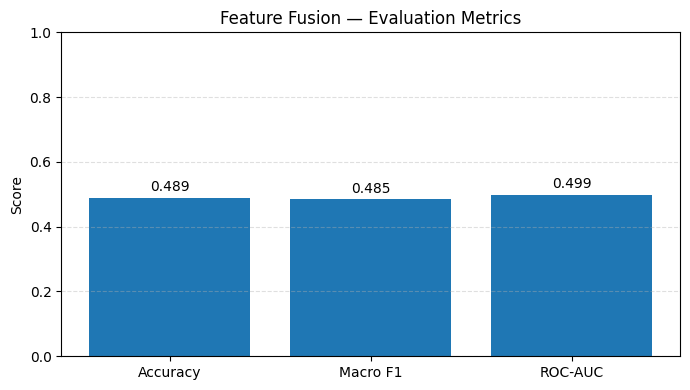

In [35]:
metrics = {
    "Accuracy": fusion_metrics["accuracy"],
    "Macro F1": fusion_metrics["f1"],
    "ROC-AUC": fusion_metrics.get("roc_auc", np.nan)
}

plt.figure(figsize=(7, 4))
bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Feature Fusion — Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, metrics.values()):
    if np.isfinite(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

## 19. Download Models and charts

Export directory: /kaggle/working/deepfake_detection_export
Saved: /kaggle/working/deepfake_detection_export/models/original_cnn.pth
Saved: /kaggle/working/deepfake_detection_export/models/gan_enhanced_cnn.pth
Saved: /kaggle/working/deepfake_detection_export/models/feature_fusion.pth

All three model checkpoints saved.

MODEL PERFORMANCE


,Model,Accuracy,Macro F1,ROC-AUC
0,Original CNN,0.527,0.525348,0.559444
1,GAN-Enhanced CNN,0.511,0.510255,0.546756
2,Feature Fusion,0.489,0.484733,0.499252


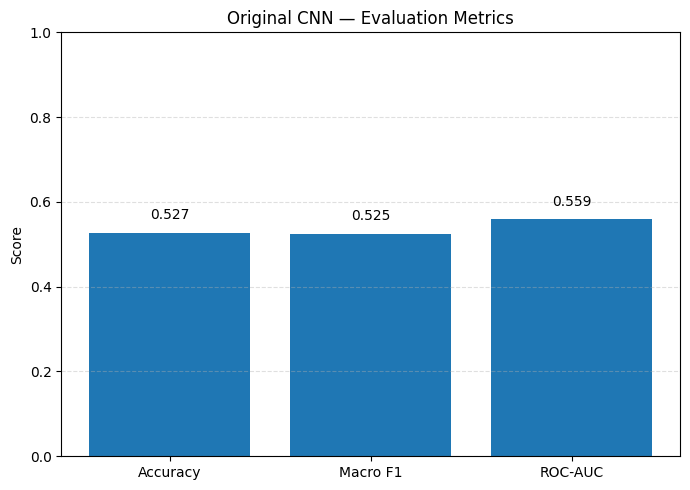

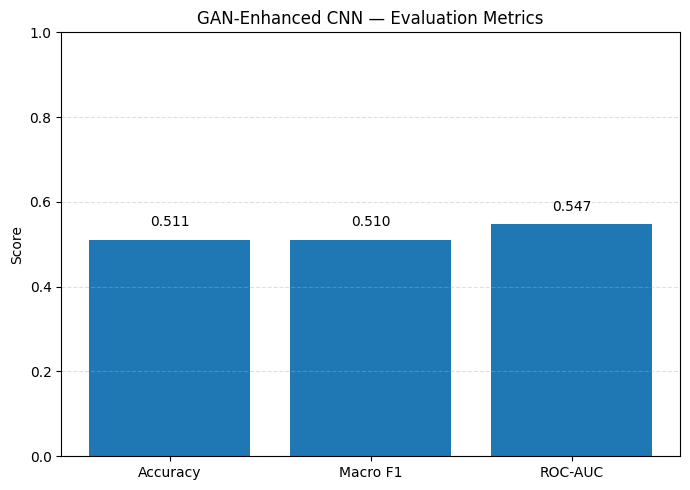

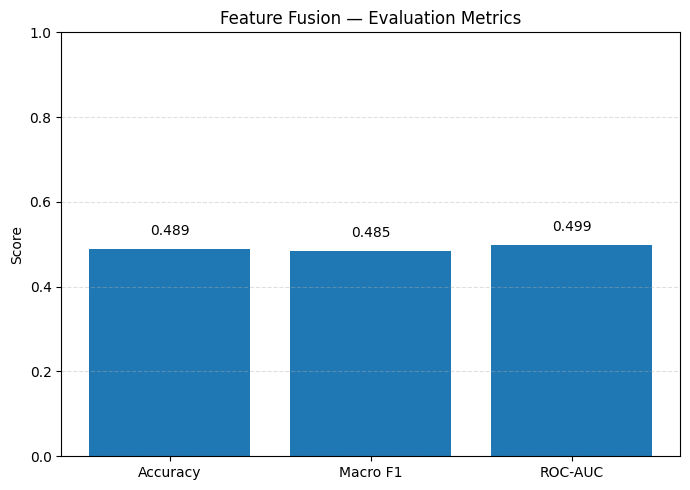

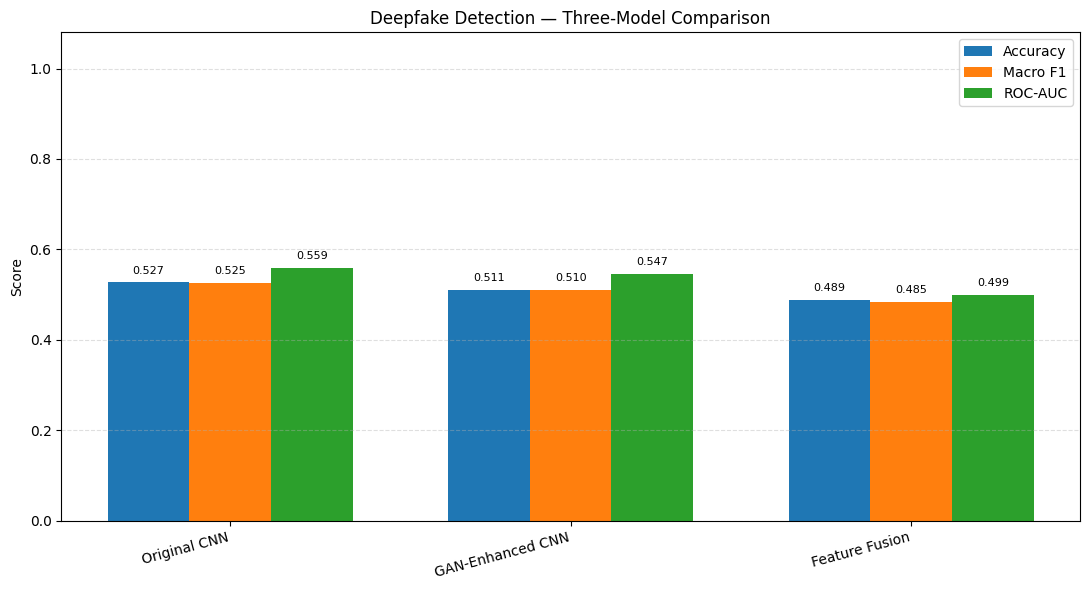


EXPORT COMPLETE
Models saved: 3
Charts directory: /kaggle/working/deepfake_detection_export/charts
Metrics directory: /kaggle/working/deepfake_detection_export/metrics
Configuration: /kaggle/working/deepfake_detection_export/config
ZIP package: /kaggle/working/deepfake_detection_export.zip

Exported files:
  README.txt
  charts/all_models_comparison.png
  charts/feature_fusion_metrics.png
  charts/gan_enhanced_cnn_metrics.png
  charts/original_cnn_metrics.png
  config/deployment_config.json
  metrics/feature_fusion_classification_report.txt
  metrics/gan_enhanced_cnn_classification_report.txt
  metrics/model_comparison.csv
  metrics/model_comparison.json
  metrics/original_cnn_classification_report.txt
  models/feature_fusion.pth
  models/gan_enhanced_cnn.pth
  models/original_cnn.pth

Download the ZIP file from the Kaggle output panel:
/kaggle/working/deepfake_detection_export.zip


In [36]:
import os
import json
import shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CREATE EXPORT DIRECTORIES
# ------------------------------------------------------------

EXPORT_DIR = Path("/kaggle/working/deepfake_detection_export")

MODEL_DIR = EXPORT_DIR / "models"
CHART_DIR = EXPORT_DIR / "charts"
METRIC_DIR = EXPORT_DIR / "metrics"
CONFIG_DIR = EXPORT_DIR / "config"

for directory in [MODEL_DIR, CHART_DIR, METRIC_DIR, CONFIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Export directory:", EXPORT_DIR)


# ------------------------------------------------------------
# 2. SAVE THE THREE TRAINED MODELS
# ------------------------------------------------------------

models = {
    "original_cnn": model_original,
    "gan_enhanced_cnn": model_enhanced,
    "feature_fusion": model_fusion,
}

for model_name, model in models.items():

    model_path = MODEL_DIR / f"{model_name}.pth"

    # Save weights and model state, not the entire Python object.
    torch.save(
        {
            "model_name": model_name,
            "state_dict": unwrap_model(model).state_dict(),
            "class_names": ["Real", "Fake"],
            "class_to_idx": {
                "Real": 0,
                "Fake": 1
            }
        },
        model_path
    )

    print(f"Saved: {model_path}")

print("\nAll three model checkpoints saved.")


# ------------------------------------------------------------
# 3. COLLECT EVALUATION METRICS
# ------------------------------------------------------------

metrics_by_model = {
    "Original CNN": original_metrics,
    "GAN-Enhanced CNN": enhanced_metrics,
    "Feature Fusion": fusion_metrics,
}

metric_rows = []

for model_name, metrics in metrics_by_model.items():

    metric_rows.append({
        "Model": model_name,
        "Accuracy": metrics.get("accuracy", np.nan),
        "Macro F1": metrics.get("f1", np.nan),
        "ROC-AUC": metrics.get("roc_auc", np.nan)
    })

results_df = pd.DataFrame(metric_rows)

print("\nMODEL PERFORMANCE")
display(results_df)


# Save CSV
results_df.to_csv(
    METRIC_DIR / "model_comparison.csv",
    index=False
)


# Save JSON
def convert_to_json_safe(value):
    if isinstance(value, dict):
        return {
            str(k): convert_to_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [convert_to_json_safe(v) for v in value]

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None

    if isinstance(value, np.ndarray):
        return convert_to_json_safe(value.tolist())

    if isinstance(value, (np.bool_,)):
        return bool(value)

    return value


with open(METRIC_DIR / "model_comparison.json", "w") as f:
    json.dump(
        convert_to_json_safe(results_df.to_dict(orient="records")),
        f,
        indent=4
    )


# Save classification reports where available
for model_name, metrics in metrics_by_model.items():

    report = metrics.get("report")

    if report is not None:
        safe_name = (
            model_name.lower()
            .replace("-", "_")
            .replace(" ", "_")
        )

        with open(
            METRIC_DIR / f"{safe_name}_classification_report.txt",
            "w"
        ) as f:
            f.write(str(report))


# ------------------------------------------------------------
# 4. SAVE AN INDIVIDUAL PERFORMANCE CHART FOR EACH MODEL
# ------------------------------------------------------------

metric_columns = ["Accuracy", "Macro F1", "ROC-AUC"]

for _, row in results_df.iterrows():

    model_name = row["Model"]

    values = [
        row["Accuracy"],
        row["Macro F1"],
        row["ROC-AUC"]
    ]

    fig, ax = plt.subplots(figsize=(7, 5))

    bars = ax.bar(metric_columns, values)

    ax.set_title(f"{model_name} — Evaluation Metrics")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    for bar, value in zip(bars, values):

        if pd.notna(value) and np.isfinite(value):

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                min(value + 0.025, 0.96),
                f"{value:.3f}",
                ha="center",
                va="bottom"
            )
        else:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                0.04,
                "N/A",
                ha="center"
            )

    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    fig.savefig(
        CHART_DIR / f"{filename}_metrics.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 5. SAVE COMPARISON CHART FOR ALL THREE MODELS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(results_df))
width = 0.24

for i, metric in enumerate(metric_columns):

    values = pd.to_numeric(
        results_df[metric],
        errors="coerce"
    ).to_numpy(dtype=float)

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric
    )

    for bar, value in zip(bars, values):

        if np.isfinite(value):

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                min(value + 0.015, 0.97),
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=8
            )

ax.set_title("Deepfake Detection — Three-Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

fig.savefig(
    CHART_DIR / "all_models_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 6. SAVE AVAILABLE MODEL CONFIGURATION
# ------------------------------------------------------------

# These are placeholders to be replaced with the EXACT
# settings used in your training notebook.

config = {
    "project": "Deepfake Detection",
    "models": [
        "original_cnn",
        "gan_enhanced_cnn",
        "feature_fusion"
    ],
    "class_names": {
        "0": "Real",
        "1": "Fake"
    },
    "model_checkpoint_format": "PyTorch state_dict",
    "device_used_for_export": str(DEVICE),
    "input_size": None,
    "normalization": None,
    "preprocessing": None,
    "architecture_definitions_required": True,
    "notes": [
        "Fill input_size with the exact training image dimensions.",
        "Fill normalization with the exact training normalization.",
        "Preserve the original architecture definitions.",
        "The GAN-enhanced model requires the correct enhancement pipeline.",
        "The feature fusion model requires both original and enhanced inputs."
    ]
}

with open(CONFIG_DIR / "deployment_config.json", "w") as f:
    json.dump(config, f, indent=4)


# ------------------------------------------------------------
# 7. SAVE A README FOR FUTURE APPLICATION DEVELOPMENT
# ------------------------------------------------------------

readme = """
DEEPFAKE DETECTION EXPORT
=========================

models/
    original_cnn.pth
    gan_enhanced_cnn.pth
    feature_fusion.pth

charts/
    original_cnn_metrics.png
    gan_enhanced_cnn_metrics.png
    feature_fusion_metrics.png
    all_models_comparison.png

metrics/
    model_comparison.csv
    model_comparison.json
    Individual classification reports, when available

config/
    deployment_config.json

IMPORTANT
---------
1. These .pth files contain model state dictionaries.
2. Recreate each model using its original architecture definition
   before loading its state dictionary.
3. Use the exact input dimensions and preprocessing from training.
4. The GAN-enhanced model requires its enhancement pipeline.
5. The feature fusion model requires both original and enhanced
   inputs in the expected format.
6. Validate inference against the notebook before deployment.
7. Do not treat validation metrics as independent test results
   unless they were obtained from a separate test set.
"""

with open(EXPORT_DIR / "README.txt", "w") as f:
    f.write(readme)


# ------------------------------------------------------------
# 8. PACKAGE EVERYTHING INTO A ZIP FILE
# ------------------------------------------------------------

ZIP_BASE = Path("/kaggle/working/deepfake_detection_export")

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=EXPORT_DIR
)

print("\n" + "=" * 60)
print("EXPORT COMPLETE")
print("=" * 60)

print("Models saved:", len(models))
print("Charts directory:", CHART_DIR)
print("Metrics directory:", METRIC_DIR)
print("Configuration:", CONFIG_DIR)
print("ZIP package:", zip_path)

print("\nExported files:")

for path in sorted(EXPORT_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(EXPORT_DIR)}")

print("\nDownload the ZIP file from the Kaggle output panel:")
print(zip_path)